In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/Carseats.csv"

print("Ready to load the dataset!")

Ready to load the dataset!


In [4]:
url = "https://raw.githubusercontent.com/justmarkham/DAT8/master/data/used_cars.csv"

print("Checking dataset URL...")

import requests

response = requests.get(url)
print("Status code:", response.status_code)

Checking dataset URL...
Status code: 404


In [5]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/CarPrice_Assignment.csv"

try:
    df = pd.read_csv(url)
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    display(df.head())
except Exception as e:
    print("Error:", e)

Error: HTTP Error 404: Not Found


In [6]:
url = "https://raw.githubusercontent.com/ameenmanna8824/DATASETS/main/CarPrice_Assignment.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (205, 26)

First 5 rows:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [7]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        205 non-null    

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [8]:
# Check and remove duplicate records
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

# Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum().sum())

# Fill missing numerical values with their median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with their mode
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:", df.isnull().sum().sum())
print("Dataset shape after cleaning:", df.shape)

Duplicate rows: 0

Missing values before cleaning:
0

Missing values after cleaning: 0
Dataset shape after cleaning: (205, 26)


C:\Users\Sharayu\AppData\Local\Temp\ipykernel_8048\1982564304.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


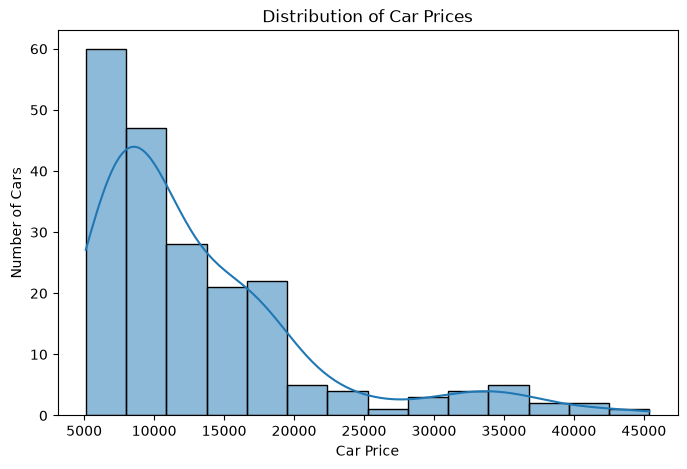

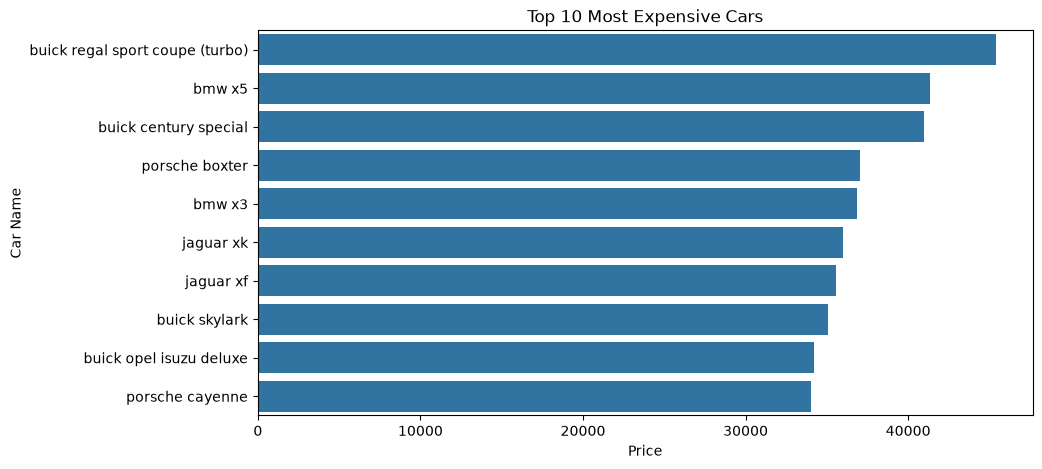

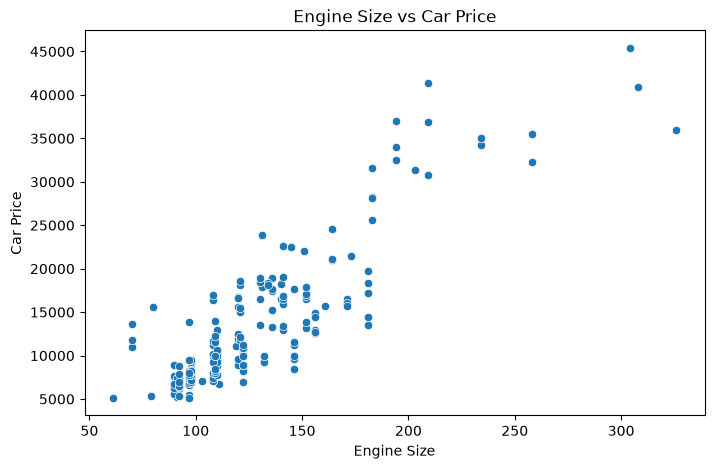

In [9]:
# 1. Distribution of car prices
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], kde=True)
plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.show()

# 2. Top 10 most expensive car models
top_cars = df.nlargest(10, "price")

plt.figure(figsize=(10, 5))
sns.barplot(data=top_cars, x="price", y="CarName")
plt.title("Top 10 Most Expensive Cars")
plt.xlabel("Price")
plt.ylabel("Car Name")
plt.show()

# 3. Engine size vs car price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="enginesize", y="price")
plt.title("Engine Size vs Car Price")
plt.xlabel("Engine Size")
plt.ylabel("Car Price")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Remove columns that are identifiers or contain car names
X = df.drop(columns=["price", "car_ID", "CarName"], errors="ignore")
y = df["price"]

# Convert categorical features into numerical values
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data preparation completed!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Target variable: price")

Data preparation completed!
Training data shape: (164, 43)
Testing data shape: (41, 43)
Target variable: price


In [11]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Predict car prices for test data
y_pred = model.predict(X_test)

print("Model training completed successfully!")
print("Number of training records:", len(X_train))
print("Number of test records:", len(X_test))

Model training completed successfully!
Number of training records: 164
Number of test records: 41


In [12]:
# Calculate model evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Score (%):", round(r2 * 100, 2), "%")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 2089.38
Root Mean Squared Error (RMSE): 2912.39
R2 Score: 0.8926
R2 Score (%): 89.26 %


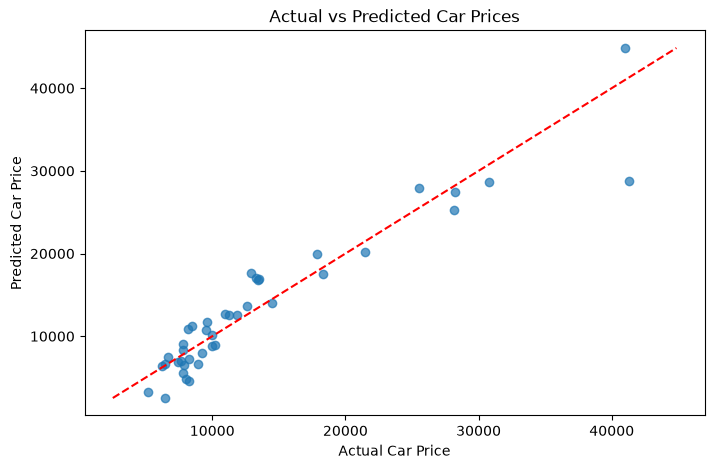

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line for perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--"
)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices")
plt.show()

In [14]:
# Select one car from the test dataset
sample_car = X_test.iloc[[0]]

# Predict its price
predicted_price = model.predict(sample_car)[0]

print("Sample Car Price Prediction")
print("---------------------------")
print("Predicted Price:", round(predicted_price, 2))
print("Actual Price:", round(float(y_test.iloc[0]), 2))

Sample Car Price Prediction
---------------------------
Predicted Price: 28611.52
Actual Price: 30760.0


In [15]:
import joblib

joblib.dump(model, "car_price_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [16]:
results.to_csv("car_price_prediction_results.csv", index=False)

print("Prediction results saved successfully!")

NameError: name 'results' is not defined

In [17]:
# Create the prediction results table
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": np.round(y_pred, 2)
})

results["Absolute Error"] = np.abs(
    results["Actual Price"] - results["Predicted Price"]
)

# Save the results to a CSV file
results.to_csv("car_price_prediction_results.csv", index=False)

print("Prediction results saved successfully!")
display(results.head())

Prediction results saved successfully!


,Actual Price,Predicted Price,Absolute Error
0,30760.000,28611.52,2148.480
1,17859.167,19979.31,2120.143
2,9549.000,10737.02,1188.020
3,11850.000,12610.95,760.950
4,28248.000,27503.96,744.040


In [18]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\Sharayu
['.anaconda', '.cache', '.codex', '.conda', '.continuum', '.copilot', '.ipynb_checkpoints', '.ipython', '.jupyter', '.python_history', '.vscode', '.vscode-shared', 'anaconda_projects', 'AppData', 'Application Data', 'car_price_prediction_model.pkl', 'car_price_prediction_results.csv', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'Favorites', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{81870f11-670a-11f1-9b19-ec3a56ac3d75}.TM.blf', 'NTUSER.DAT{81870f11-670a-11f1-9b19-ec3a56ac3d75}.TM.blf.cnpf', 'NTUSER.DAT{81870f11-670a-11f1-9b19-ec3a56ac3d75}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{81870f11-670a-11f1-9b19-ec3a56ac3d75}.TMContainer00000000000000000001.regtrans-ms.cnpf', 'NTUSER.DAT{81870f11-670a-11f1-9b19-ec3a56ac3d75}.TMContainer00000000000000000002.regtrans-ms', 'NTUSER.DAT{81870f11-670a-11f1-9b19-ec3a56ac3d75}.TMContainer00000000000000000002.regtrans-ms.cnpf', 'nt